# xG Feature Checks

Verifies `src/processing/xg_processing.py` before any modeling.
Re-run top to bottom whenever that file changes.

**Sections**
1. Setup
2. Unit tests on tiny hand-made inputs (strength decoding, geometry)
3. Row counts and goal rate
4. Missing values and data types
5. Coordinate normalization
6. Goal rate by distance and angle *(the most important check)*
7. Goal rate by strength state

Each check prints **PASS** or **CHECK**. A CHECK isn't always a bug; read the note next to it.

## 1. Setup

In [25]:
%load_ext autoreload
%autoreload 2

import sys; sys.path.insert(0, "..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data.db import get_connection
from src.processing.xg_processing import (
    load_shots, normalize_coordinates, add_geometry, decode_strength,
    build_xg_features, FEATURE_COLS, TARGET_COL, CATEGORICAL_COLS,
)

def check(label, ok, note=""):
    print(f"{'PASS ' if ok else 'CHECK'}  {label}" + (f"   ({note})" if note else ""))

conn = get_connection()
raw  = load_shots(conn)                                   # before any processing
norm = add_geometry(decode_strength(normalize_coordinates(raw)))   # every row, all helper columns
feat = build_xg_features(conn)                            # the final training table
print(f"raw: {len(raw):,} rows   feat: {len(feat):,} rows")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
raw: 566,545 rows   feat: 562,374 rows


## 2. Unit tests

Tiny inputs where the right answer is known by hand. If these fail, nothing below can be trusted.

`situation_code` order: away goalie, away skaters, home skaters, home goalie.

In [26]:
test = pd.DataFrame({
    "situation_code": ["1551", "1451", "1451", "0651", "1560"],
    "team_id":        [1,      1,      2,      1,      1],
    "home_team_id":   [1,      1,      1,      1,      1],
})
out = decode_strength(test)
print(out[["situation_code", "team_id", "skater_diff", "total_skaters",
           "empty_net", "own_goalie_pulled"]].to_string(index=False))

expected_diff  = [0, 1, -1, -1, 1]
expected_total = [10, 9, 9, 11, 11]
expected_en    = [False, False, False, True, False]
expected_pull  = [0, 0, 0, 0, 1]
print()
check("skater_diff",       out.skater_diff.tolist() == expected_diff)
check("total_skaters",     out.total_skaters.tolist() == expected_total)
check("empty_net",         out.empty_net.tolist() == expected_en)
check("own_goalie_pulled", out.own_goalie_pulled.tolist() == expected_pull)

situation_code  team_id  skater_diff  total_skaters  empty_net  own_goalie_pulled
          1551        1            0             10      False                  0
          1451        1            1              9      False                  0
          1451        2           -1              9      False                  0
          0651        1           -1             11       True                  0
          1560        1            1             11      False                  1

PASS   skater_diff
PASS   total_skaters
PASS   empty_net
PASS   own_goalie_pulled


In [27]:
geo = add_geometry(pd.DataFrame({
    "x_coord": [59,  89,  59,  95],
    "y_coord": [0,   20, -30,  5],
}))
print(geo.round(1).to_string(index=False))
print()
check("30 ft straight out -> 30 ft, 0 deg",  np.isclose(geo.distance[0], 30) and np.isclose(geo.angle[0], 0))
check("on the goal line -> 90 deg",          np.isclose(geo.angle[1], 90))
check("left/right symmetric (|y| used)",     np.isclose(geo.angle[2], 45))
check("behind the net -> angle over 90",     geo.angle[3] > 90)

 x_coord  y_coord  distance  angle
      59        0      30.0    0.0
      89       20      20.0   90.0
      59      -30      42.4   45.0
      95        5       7.8  140.2

PASS   30 ft straight out -> 30 ft, 0 deg
PASS   on the goal line -> 90 deg
PASS   left/right symmetric (|y| used)
PASS   behind the net -> angle over 90


## 3. Row counts and goal rate

`raw` should match `shot_context` (566,545). `feat` is smaller by the empty-net shots that were dropped.

In [28]:
dropped = len(raw) - len(feat)
goal_rate = feat[TARGET_COL].mean()

print(f"raw shots:          {len(raw):>9,}")
print(f"empty-net dropped:  {dropped:>9,}  ({dropped / len(raw):.1%})")
print(f"training rows:      {len(feat):>9,}")
print(f"goal rate:          {goal_rate:>9.2%}")
print()
check("raw row count", len(raw) == 566_545, "should equal shot_context rows")
check("empty-net drop is small", 0 < dropped / len(raw) < 0.05, "expect roughly 1-3%")
check("goal rate plausible", 0.05 < goal_rate < 0.09, "expect about 7%")

raw shots:            566,545
empty-net dropped:      4,171  (0.7%)
training rows:        562,374
goal rate:              6.77%

PASS   raw row count   (should equal shot_context rows)
PASS   empty-net drop is small   (expect roughly 1-3%)
PASS   goal rate plausible   (expect about 7%)


## 4. Missing values and data types

Only `last_event_type` and `time_since_last_event` should have missing values: the first shot after a stoppage has no prior event in its chain.

In [29]:
nulls = feat[FEATURE_COLS + [TARGET_COL]].isna().sum()
print(nulls.to_string())
print()
allowed = {"last_event_type", "time_since_last_event"}
unexpected = [c for c, n in nulls.items() if n > 0 and c not in allowed]
check("no unexpected NULLs", not unexpected, f"unexpected: {unexpected}" if unexpected else "")
for col in CATEGORICAL_COLS:
    check(f"{col} is category", str(feat[col].dtype) == "category")
check("time_since_last_event is numeric", pd.api.types.is_float_dtype(feat.time_since_last_event))

distance                      0
angle                         0
shot_type                     0
is_rebound                    0
is_rush                       0
last_event_type          138913
time_since_last_event    138913
skater_diff                   0
total_skaters                 0
own_goalie_pulled             0
is_goal                       0

PASS   no unexpected NULLs
PASS   shot_type is category
PASS   last_event_type is category
PASS   time_since_last_event is numeric


## 5. Coordinate normalization

After flipping, nearly every offensive-zone shot should sit past the blue line at x = 25, and the plot should cluster at the right-hand net.

In [30]:
o = norm[norm.zone_code == "O"]
share = (o.x_coord > 25).mean()
print(f"offensive-zone shots past the blue line: {share:.3%}")
check("normalization", share > 0.995, "expect about 99.9%")

own_end = (norm[~norm.empty_net].x_coord < -25).sum()
print(f"\nshots from the shooter's own end, empty nets excluded: {own_end:,}")
print("(before dropping empty nets this was about 9,100; most were clears at an empty net)")

offensive-zone shots past the blue line: 99.909%
PASS   normalization   (expect about 99.9%)

shots from the shooter's own end, empty nets excluded: 7,637
(before dropping empty nets this was about 9,100; most were clears at an empty net)


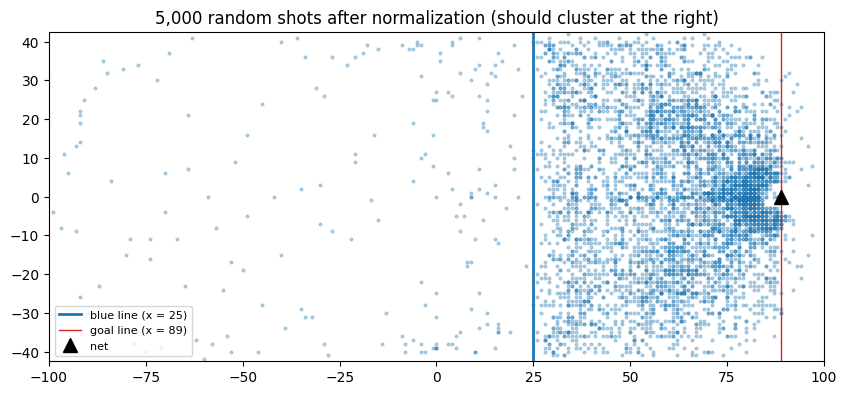

In [31]:
s = norm[~norm.empty_net].sample(5000, random_state=0)
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.scatter(s.x_coord, s.y_coord, s=4, alpha=0.3)
ax.axvline(25, color="tab:blue", lw=2, label="blue line (x = 25)")
ax.axvline(89, color="tab:red", lw=1, label="goal line (x = 89)")
ax.plot(89, 0, "k^", ms=10, label="net")
ax.set_xlim(-100, 100); ax.set_ylim(-42.5, 42.5); ax.set_aspect("equal")
ax.set_title("5,000 random shots after normalization (should cluster at the right)")
ax.legend(loc="lower left", fontsize=8)
plt.show()

## 6. Goal rate by distance and angle

**The most important check.** Goal rate should fall steadily as distance grows, and as the angle widens. If it doesn't, the geometry or the normalization is wrong and no model will fix it.

In [32]:
dist_bins = [0, 10, 20, 30, 40, 50, 60, 200]
by_dist = (feat.groupby(pd.cut(feat.distance, dist_bins), observed=True)[TARGET_COL]
               .agg(shots="size", goal_rate="mean"))
print(by_dist.assign(goal_rate=by_dist.goal_rate.map("{:.1%}".format)).to_string())
print()
rates = by_dist.goal_rate.values
check("goal rate falls with distance", all(np.diff(rates) < 0), "each bin lower than the one before")
check("close shots score most", rates[0] > 2* goal_rate, "0-10 ft should be several times the average")
print(f"\nmedian distance: {feat.distance.median():.1f} ft  (expect roughly 25-35)")

           shots goal_rate
distance                  
(0, 10]    71477     14.4%
(10, 20]   99274     10.8%
(20, 30]   89470      8.8%
(30, 40]   97371      5.6%
(40, 50]   76053      2.8%
(50, 60]   68328      1.9%
(60, 200]  60398      0.8%

PASS   goal rate falls with distance   (each bin lower than the one before)
PASS   close shots score most   (0-10 ft should be several times the average)

median distance: 32.1 ft  (expect roughly 25-35)


In [33]:
# Angle and distance are tangled: wide-angle shots are usually taken close to the
# goal line, so they look dangerous in a raw table. Compare angles only among shots
# from a similar distance (15-35 ft) so the angle effect shows on its own.
mid = feat[feat.distance.between(15, 35)]
angle_bins = [0, 15, 30, 45, 60, 90]
by_angle = (mid.groupby(pd.cut(mid.angle, angle_bins), observed=True)[TARGET_COL]
               .agg(shots="size", goal_rate="mean"))
print("shots from 15-35 ft only")
print(by_angle.assign(goal_rate=by_angle.goal_rate.map("{:.1%}".format)).to_string())
print()
r = by_angle.goal_rate.values
check("at the same distance, wide angles score less", r[-1] < r[0])

shots from 15-35 ft only
          shots goal_rate
angle                    
(0, 15]   35092     11.4%
(15, 30]  36866     10.1%
(30, 45]  45701      8.8%
(45, 60]  30834      6.8%
(60, 90]  28213      3.8%

PASS   at the same distance, wide angles score less


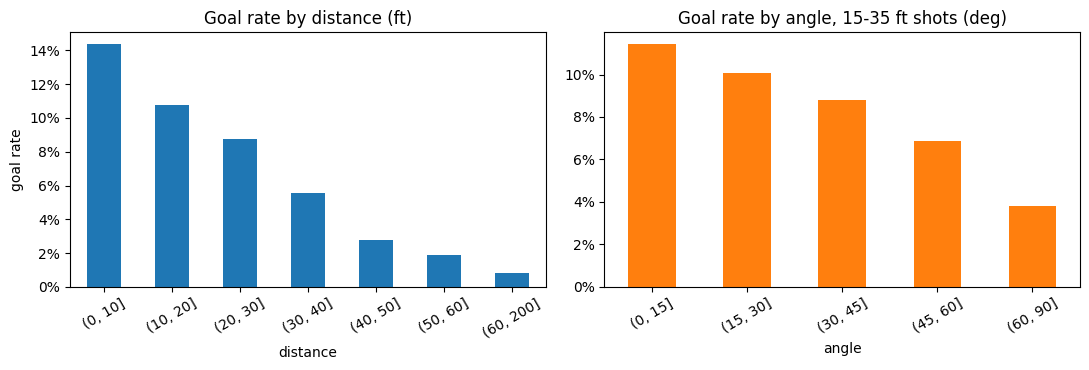

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
by_dist.goal_rate.plot.bar(ax=axes[0], color="tab:blue")
axes[0].set_title("Goal rate by distance (ft)"); axes[0].set_ylabel("goal rate")
by_angle.goal_rate.plot.bar(ax=axes[1], color="tab:orange")
axes[1].set_title("Goal rate by angle, 15-35 ft shots (deg)")
for ax in axes:
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

## 7. Goal rate by strength state

About 80% of shots should be even strength, power-play shots (+1) should clearly outnumber shorthanded ones (−1), and power-play shots should score more often than even-strength shots.

In [35]:
by_str = (feat.groupby("skater_diff")[TARGET_COL]
              .agg(shots="size", goal_rate="mean"))
by_str["share"] = by_str.shots / by_str.shots.sum()
print(by_str.assign(share=by_str.share.map("{:.1%}".format),
                    goal_rate=by_str.goal_rate.map("{:.1%}".format)).to_string())
print()
check("even strength is most shots", 0.70 < by_str.loc[0, "shots"] / len(feat) < 0.88)
check("PP shots outnumber SH shots", by_str.loc[1, "shots"] > by_str.loc[-1, "shots"])
check("PP converts better than even", by_str.loc[1, "goal_rate"] > by_str.loc[0, "goal_rate"])

              shots goal_rate  share
skater_diff                         
-2               56      1.8%   0.0%
-1            13325      7.3%   2.4%
 0           456462      6.2%  81.2%
 1            88640      9.5%  15.8%
 2             3876     13.3%   0.7%
 3               15      6.7%   0.0%

PASS   even strength is most shots
PASS   PP shots outnumber SH shots
PASS   PP converts better than even


In [36]:
print(feat.total_skaters.value_counts().sort_index().to_string())
print("\n10 = 5v5 (most), 9 = 5v4, 8 = 4v4, 6 = 3v3 overtime, 11 = extra attacker")

total_skaters
1        194
6       6198
7       1635
8       8727
9      89117
10    445469
11     11034

10 = 5v5 (most), 9 = 5v4, 8 = 4v4, 6 = 3v3 overtime, 11 = extra attacker


---
If sections 2, 5 and 6 all pass, the feature table is ready for the baseline model (logistic regression on distance and angle).